
Running: PMX
Best Route: [3, 8, 1, 0, 7, 2, 6, 5, 9, 4]
Best Distance: 232.39

Running: OX
Best Route: [0, 1, 8, 3, 4, 9, 5, 6, 2, 7]
Best Distance: 232.39

Running: CX2
Best Route: [2, 3, 4, 9, 5, 6, 7, 0, 8, 1]
Best Distance: 237.38

FINAL COMPARISON
PMX   : Distance = 232.39
OX    : Distance = 232.39
CX2   : Distance = 237.38


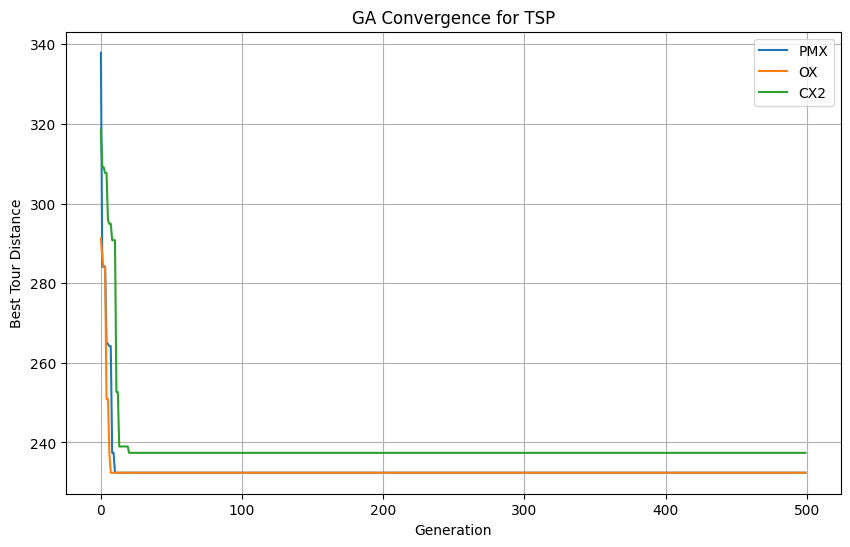

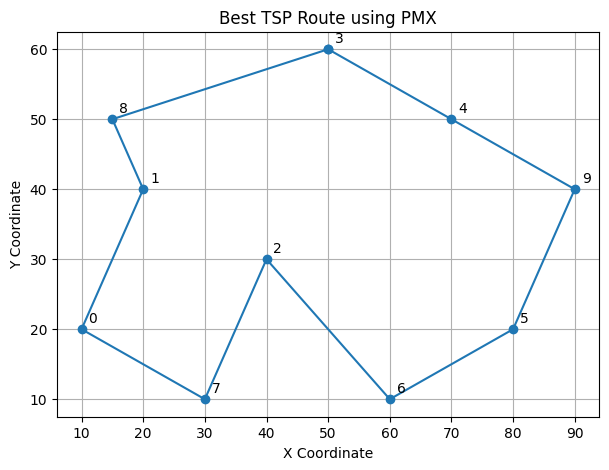

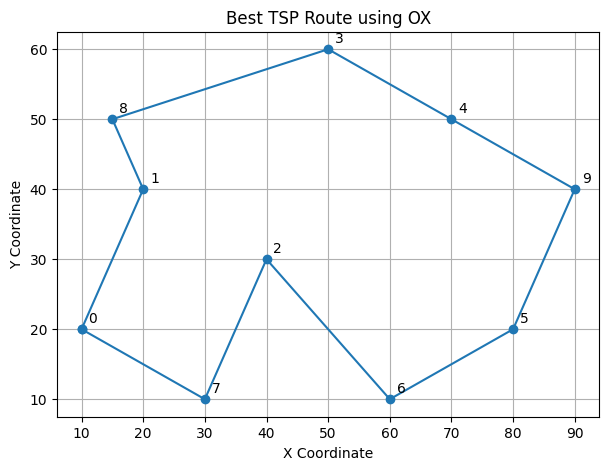

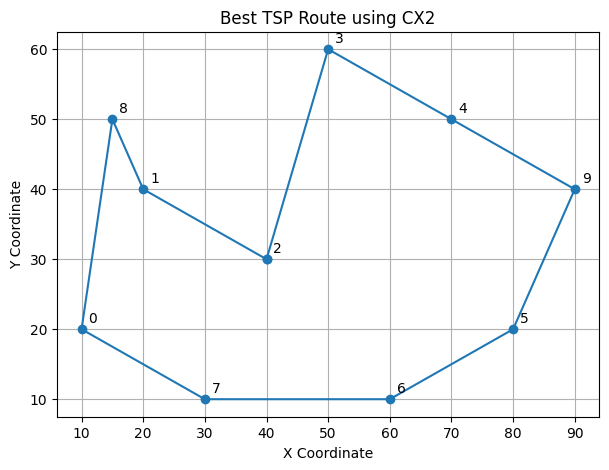

In [1]:
import random
import math
import matplotlib.pyplot as plt


# ============================================================
# 1. TSP DATA
# ============================================================

# Example city coordinates
# You can replace these with TSPLIB coordinates later.
cities = {
    0: (10, 20),
    1: (20, 40),
    2: (40, 30),
    3: (50, 60),
    4: (70, 50),
    5: (80, 20),
    6: (60, 10),
    7: (30, 10),
    8: (15, 50),
    9: (90, 40)
}


# ============================================================
# 2. DISTANCE FUNCTION
# ============================================================

def distance(city1, city2):
    x1, y1 = cities[city1]
    x2, y2 = cities[city2]

    return math.sqrt((x1 - x2) ** 2 + (y1 - y2) ** 2)


def tour_distance(route):
    total = 0

    for i in range(len(route)):
        current_city = route[i]
        next_city = route[(i + 1) % len(route)]

        total += distance(current_city, next_city)

    return total


# ============================================================
# 3. INITIAL POPULATION
# ============================================================

def create_population(population_size):
    population = []

    city_list = list(cities.keys())

    for _ in range(population_size):
        route = city_list.copy()
        random.shuffle(route)
        population.append(route)

    return population


# ============================================================
# 4. FITNESS
# ============================================================

def fitness(route):
    # Smaller distance = better fitness
    return 1 / tour_distance(route)


# ============================================================
# 5. TOURNAMENT SELECTION
# ============================================================

def tournament_selection(population, tournament_size=3):

    selected = random.sample(population, tournament_size)

    selected.sort(key=tour_distance)

    return selected[0]


# ============================================================
# 6. PMX CROSSOVER
# ============================================================

def pmx(parent1, parent2):

    size = len(parent1)

    child = [None] * size

    start, end = sorted(random.sample(range(size), 2))

    # Copy section from parent 1
    child[start:end] = parent1[start:end]

    # Mapping
    for i in range(start, end):

        if parent2[i] not in child:

            position = i

            while True:

                value = parent1[position]

                position = parent2.index(value)

                if child[position] is None:
                    child[position] = parent2[i]
                    break

    # Fill remaining positions
    for i in range(size):

        if child[i] is None:
            child[i] = parent2[i]

    return child


# ============================================================
# 7. ORDER CROSSOVER (OX)
# ============================================================

def ox(parent1, parent2):

    size = len(parent1)

    child = [None] * size

    start, end = sorted(random.sample(range(size), 2))

    # Copy section from parent 1
    child[start:end] = parent1[start:end]

    # Get remaining values from parent 2
    remaining = [
        city for city in parent2
        if city not in child
    ]

    index = end % size

    for city in remaining:

        while child[index] is not None:
            index = (index + 1) % size

        child[index] = city

    return child


# ============================================================
# 8. CYCLE CROSSOVER (CX)
# ============================================================

def cx(parent1, parent2):

    size = len(parent1)

    child = [None] * size

    visited = [False] * size

    cycle_number = 0

    for start in range(size):

        if visited[start]:
            continue

        index = start
        cycle = []

        while not visited[index]:

            visited[index] = True
            cycle.append(index)

            value = parent2[index]
            index = parent1.index(value)

        # Alternate parents for each cycle
        if cycle_number % 2 == 0:

            for index in cycle:
                child[index] = parent1[index]

        else:

            for index in cycle:
                child[index] = parent2[index]

        cycle_number += 1

    return child


# ============================================================
# 9. MODIFIED CYCLE CROSSOVER - CX2
# ============================================================

def cx2(parent1, parent2):

    size = len(parent1)

    child1 = [None] * size
    child2 = [None] * size

    unused = set(range(size))

    cycle_number = 0

    while unused:

        start = next(iter(unused))

        cycle = []

        index = start

        while index in unused:

            cycle.append(index)
            unused.remove(index)

            # Follow the relationship between parents
            value = parent2[index]

            index = parent1.index(value)

        # Alternate the source parent
        if cycle_number % 2 == 0:

            for index in cycle:
                child1[index] = parent1[index]
                child2[index] = parent2[index]

        else:

            for index in cycle:
                child1[index] = parent2[index]
                child2[index] = parent1[index]

        cycle_number += 1

    return child1, child2


# ============================================================
# 10. MUTATION
# ============================================================

def mutation(route, mutation_rate):

    route = route.copy()

    if random.random() < mutation_rate:

        # Inversion mutation
        start, end = sorted(
            random.sample(range(len(route)), 2)
        )

        route[start:end] = reversed(route[start:end])

    return route


# ============================================================
# 11. GENETIC ALGORITHM
# ============================================================

def genetic_algorithm(
        crossover_method,
        population_size=100,
        generations=500,
        crossover_rate=0.8,
        mutation_rate=0.1
):

    population = create_population(population_size)

    best_route = min(
        population,
        key=tour_distance
    )

    best_distance = tour_distance(best_route)

    history = []

    for generation in range(generations):

        new_population = []

        # Elitism
        elite = min(
            population,
            key=tour_distance
        )

        new_population.append(elite)

        while len(new_population) < population_size:

            parent1 = tournament_selection(population)
            parent2 = tournament_selection(population)

            # Crossover
            if random.random() < crossover_rate:

                if crossover_method == "PMX":

                    child1 = pmx(parent1, parent2)
                    child2 = pmx(parent2, parent1)

                elif crossover_method == "OX":

                    child1 = ox(parent1, parent2)
                    child2 = ox(parent2, parent1)

                elif crossover_method == "CX":

                    child1 = cx(parent1, parent2)
                    child2 = cx(parent2, parent1)

                elif crossover_method == "CX2":

                    child1, child2 = cx2(
                        parent1,
                        parent2
                    )

                else:
                    raise ValueError(
                        "Unknown crossover method"
                    )

            else:

                child1 = parent1.copy()
                child2 = parent2.copy()

            # Mutation
            child1 = mutation(
                child1,
                mutation_rate
            )

            child2 = mutation(
                child2,
                mutation_rate
            )

            new_population.append(child1)

            if len(new_population) < population_size:
                new_population.append(child2)

        population = new_population

        # Best solution of generation
        current_best = min(
            population,
            key=tour_distance
        )

        current_distance = tour_distance(
            current_best
        )

        if current_distance < best_distance:

            best_route = current_best.copy()
            best_distance = current_distance

        history.append(best_distance)

    return best_route, best_distance, history


# ============================================================
# 12. RUN COMPARISON
# ============================================================

methods = [
    "PMX",
    "OX",
    "CX2"
]

results = {}

for method in methods:

    print("\nRunning:", method)

    route, distance_value, history = genetic_algorithm(
        crossover_method=method,
        population_size=100,
        generations=500,
        crossover_rate=0.8,
        mutation_rate=0.1
    )

    results[method] = (
        route,
        distance_value,
        history
    )

    print("Best Route:", route)
    print("Best Distance:", round(distance_value, 2))


# ============================================================
# 13. DISPLAY COMPARISON
# ============================================================

print("\n==============================")
print("FINAL COMPARISON")
print("==============================")

for method in methods:

    route, distance_value, history = results[method]

    print(
        f"{method:5s} : "
        f"Distance = {distance_value:.2f}"
    )


# ============================================================
# 14. CONVERGENCE GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

for method in methods:

    history = results[method][2]

    plt.plot(
        history,
        label=method
    )

plt.xlabel("Generation")
plt.ylabel("Best Tour Distance")

plt.title(
    "GA Convergence for TSP"
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# 15. PLOT BEST ROUTE
# ============================================================

for method in methods:

    route = results[method][0]

    route_with_return = route + [route[0]]

    x = [
        cities[city][0]
        for city in route_with_return
    ]

    y = [
        cities[city][1]
        for city in route_with_return
    ]

    plt.figure(figsize=(7, 5))

    plt.plot(
        x,
        y,
        marker="o"
    )

    for city in route:

        plt.annotate(
            str(city),
            cities[city],
            xytext=(5, 5),
            textcoords="offset points"
        )

    plt.title(
        f"Best TSP Route using {method}"
    )

    plt.xlabel("X Coordinate")
    plt.ylabel("Y Coordinate")

    plt.grid(True)

    plt.show()




       GENETIC ALGORITHM - TSP RESULTS

Running PMX...
PMX completed.

Running OX...
OX completed.

Running CX2...
CX2 completed.


                 FINAL RESULTS
Method    Best Distance       Best Route
------------------------------------------------------------
PMX       237.38              [4, 3, 2, 1, 8, 0, 7, 6, 5, 9]
OX        232.39              [7, 0, 1, 8, 3, 4, 9, 5, 6, 2]
CX2       237.38              [1, 2, 3, 4, 9, 5, 6, 7, 0, 8]


BEST RESULT
----------------------------------------
Crossover Method : OX
Shortest Distance: 232.39
Best Route: [7, 0, 1, 8, 3, 4, 9, 5, 6, 2]


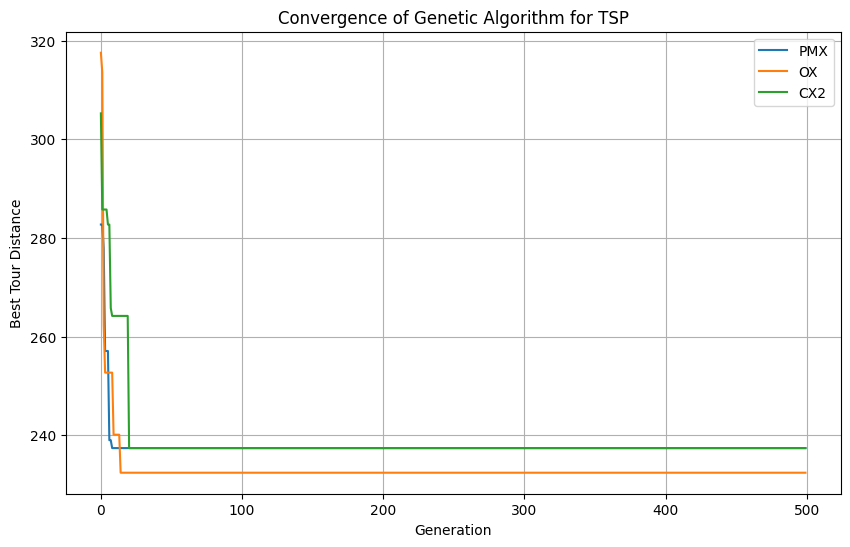

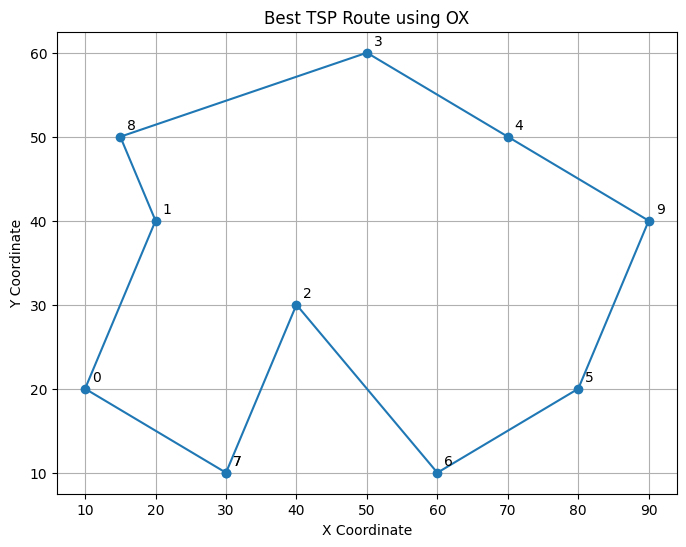

In [2]:
import random
import math
import matplotlib.pyplot as plt

# =========================================================
# TSP CITY DATA
# =========================================================

cities = {
    0: (10, 20),
    1: (20, 40),
    2: (40, 30),
    3: (50, 60),
    4: (70, 50),
    5: (80, 20),
    6: (60, 10),
    7: (30, 10),
    8: (15, 50),
    9: (90, 40)
}

# =========================================================
# DISTANCE
# =========================================================

def distance(a, b):
    x1, y1 = cities[a]
    x2, y2 = cities[b]

    return math.sqrt((x1-x2)**2 + (y1-y2)**2)


def tour_distance(route):

    total = 0

    for i in range(len(route)):
        total += distance(
            route[i],
            route[(i+1) % len(route)]
        )

    return total


# =========================================================
# INITIAL POPULATION
# =========================================================

def create_population(size):

    population = []

    for _ in range(size):

        route = list(cities.keys())

        random.shuffle(route)

        population.append(route)

    return population


# =========================================================
# SELECTION
# =========================================================

def selection(population):

    candidates = random.sample(population, 3)

    return min(candidates, key=tour_distance)


# =========================================================
# PMX
# =========================================================

def pmx(p1, p2):

    n = len(p1)

    child = [None] * n

    start, end = sorted(
        random.sample(range(n), 2)
    )

    child[start:end] = p1[start:end]

    for i in range(start, end):

        if p2[i] not in child:

            position = i

            while True:

                value = p1[position]

                position = p2.index(value)

                if child[position] is None:

                    child[position] = p2[i]

                    break

    for i in range(n):

        if child[i] is None:

            child[i] = p2[i]

    return child


# =========================================================
# OX
# =========================================================

def ox(p1, p2):

    n = len(p1)

    child = [None] * n

    start, end = sorted(
        random.sample(range(n), 2)
    )

    child[start:end] = p1[start:end]

    remaining = [
        x for x in p2
        if x not in child
    ]

    index = end % n

    for city in remaining:

        while child[index] is not None:

            index = (index + 1) % n

        child[index] = city

    return child


# =========================================================
# CX2 - MODIFIED CYCLE CROSSOVER
# =========================================================

def cx2(p1, p2):

    n = len(p1)

    child1 = [None] * n
    child2 = [None] * n

    unused = set(range(n))

    cycle = 0

    while unused:

        start = next(iter(unused))

        current = start

        positions = []

        while current in unused:

            positions.append(current)

            unused.remove(current)

            value = p2[current]

            current = p1.index(value)

        if cycle % 2 == 0:

            for pos in positions:

                child1[pos] = p1[pos]
                child2[pos] = p2[pos]

        else:

            for pos in positions:

                child1[pos] = p2[pos]
                child2[pos] = p1[pos]

        cycle += 1

    return child1, child2


# =========================================================
# MUTATION
# =========================================================

def mutation(route, rate=0.1):

    route = route.copy()

    if random.random() < rate:

        a, b = sorted(
            random.sample(range(len(route)), 2)
        )

        route[a:b] = reversed(route[a:b])

    return route


# =========================================================
# GENETIC ALGORITHM
# =========================================================

def genetic_algorithm(method):

    population_size = 100
    generations = 500
    crossover_rate = 0.8
    mutation_rate = 0.1

    population = create_population(
        population_size
    )

    best_route = min(
        population,
        key=tour_distance
    )

    best_distance = tour_distance(
        best_route
    )

    history = []

    for generation in range(generations):

        new_population = []

        # ELITISM
        elite = min(
            population,
            key=tour_distance
        )

        new_population.append(
            elite.copy()
        )

        while len(new_population) < population_size:

            parent1 = selection(population)
            parent2 = selection(population)

            # CROSSOVER

            if random.random() < crossover_rate:

                if method == "PMX":

                    child1 = pmx(parent1, parent2)
                    child2 = pmx(parent2, parent1)

                elif method == "OX":

                    child1 = ox(parent1, parent2)
                    child2 = ox(parent2, parent1)

                elif method == "CX2":

                    child1, child2 = cx2(
                        parent1,
                        parent2
                    )

            else:

                child1 = parent1.copy()
                child2 = parent2.copy()

            # MUTATION

            child1 = mutation(
                child1,
                mutation_rate
            )

            child2 = mutation(
                child2,
                mutation_rate
            )

            new_population.append(child1)

            if len(new_population) < population_size:

                new_population.append(child2)

        population = new_population

        current_best = min(
            population,
            key=tour_distance
        )

        current_distance = tour_distance(
            current_best
        )

        if current_distance < best_distance:

            best_distance = current_distance

            best_route = current_best.copy()

        history.append(best_distance)

    return best_route, best_distance, history


# =========================================================
# RUN EXPERIMENT
# =========================================================

methods = ["PMX", "OX", "CX2"]

results = {}

print("\n")
print("=" * 60)
print("       GENETIC ALGORITHM - TSP RESULTS")
print("=" * 60)

for method in methods:

    print(f"\nRunning {method}...")

    route, best_distance, history = \
        genetic_algorithm(method)

    results[method] = {
        "route": route,
        "distance": best_distance,
        "history": history
    }

    print(f"{method} completed.")


# =========================================================
# DISPLAY RESULTS
# =========================================================

print("\n")
print("=" * 60)
print("                 FINAL RESULTS")
print("=" * 60)

print(
    f"{'Method':<10}"
    f"{'Best Distance':<20}"
    f"{'Best Route'}"
)

print("-" * 60)

for method in methods:

    route = results[method]["route"]

    distance_value = results[method]["distance"]

    print(
        f"{method:<10}"
        f"{distance_value:<20.2f}"
        f"{route}"
    )

print("=" * 60)


# =========================================================
# FIND BEST METHOD
# =========================================================

best_method = min(
    methods,
    key=lambda x: results[x]["distance"]
)

print("\n")
print("BEST RESULT")
print("-" * 40)

print("Crossover Method :", best_method)

print(
    "Shortest Distance:",
    round(
        results[best_method]["distance"],
        2
    )
)

print(
    "Best Route:",
    results[best_method]["route"]
)


# =========================================================
# CONVERGENCE GRAPH
# =========================================================

plt.figure(figsize=(10, 6))

for method in methods:

    plt.plot(
        results[method]["history"],
        label=method
    )

plt.title(
    "Convergence of Genetic Algorithm for TSP"
)

plt.xlabel("Generation")

plt.ylabel("Best Tour Distance")

plt.legend()

plt.grid(True)

plt.show()


# =========================================================
# BEST ROUTE GRAPH
# =========================================================

route = results[best_method]["route"]

route = route + [route[0]]

x = [cities[i][0] for i in route]

y = [cities[i][1] for i in route]

plt.figure(figsize=(8, 6))

plt.plot(
    x,
    y,
    marker="o"
)

for city in route:

    plt.annotate(
        str(city),
        cities[city],
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title(
    f"Best TSP Route using {best_method}"
)

plt.xlabel("X Coordinate")

plt.ylabel("Y Coordinate")

plt.grid(True)

plt.show()



       GENETIC ALGORITHM FOR TRAVELLING SALESMAN PROBLEM

PMX completed.

OX completed.

CX2 completed.

                         RESULTS
Method      Best Distance       Best Route
----------------------------------------------------------------------
PMX         232.39              [0, 1, 8, 3, 4, 9, 5, 6, 2, 7]
OX          232.39              [4, 9, 5, 6, 2, 7, 0, 1, 8, 3]
CX2         237.38              [7, 0, 8, 1, 2, 3, 4, 9, 5, 6]

BEST RESULT
----------------------------------------
Crossover Method : PMX
Shortest Distance: 232.39
Best Route: [0, 1, 8, 3, 4, 9, 5, 6, 2, 7]


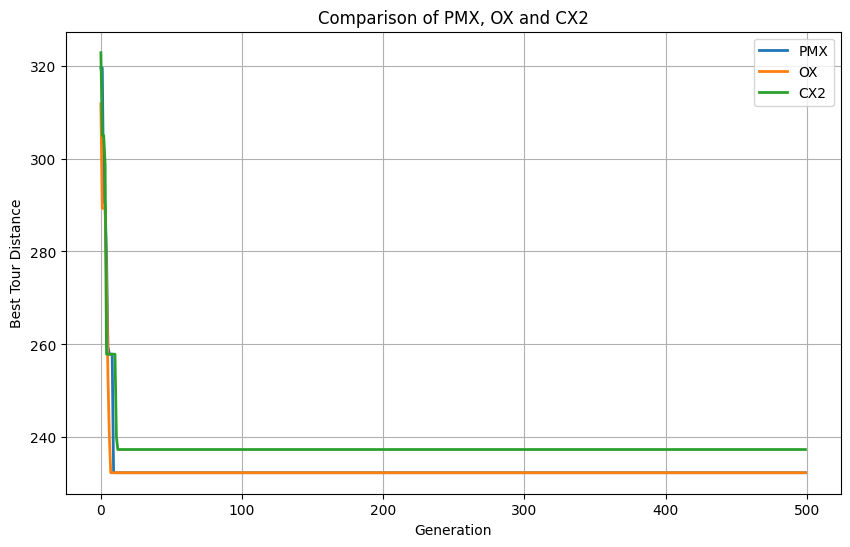

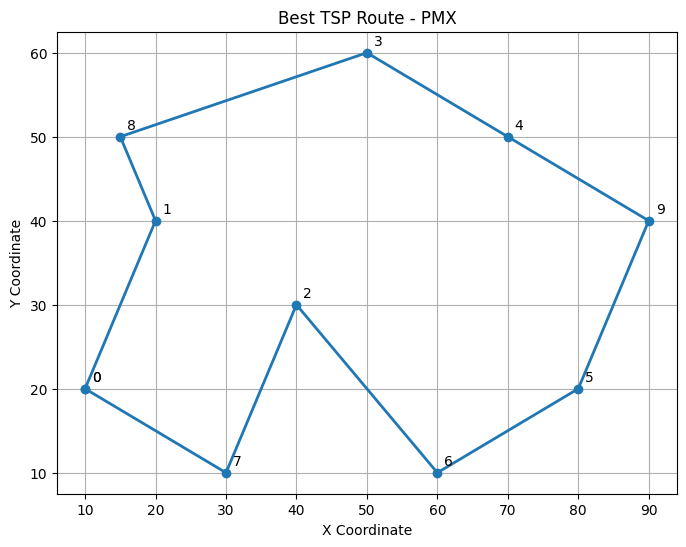

In [3]:
import random
import math
import matplotlib.pyplot as plt

# ============================================================
# TSP CITY DATA
# ============================================================

cities = {
    0: (10, 20),
    1: (20, 40),
    2: (40, 30),
    3: (50, 60),
    4: (70, 50),
    5: (80, 20),
    6: (60, 10),
    7: (30, 10),
    8: (15, 50),
    9: (90, 40)
}


# ============================================================
# DISTANCE
# ============================================================

def distance(a, b):
    x1, y1 = cities[a]
    x2, y2 = cities[b]

    return math.sqrt((x1-x2)**2 + (y1-y2)**2)


def tour_distance(route):

    total = 0

    for i in range(len(route)):
        total += distance(
            route[i],
            route[(i + 1) % len(route)]
        )

    return total


# ============================================================
# CREATE POPULATION
# ============================================================

def create_population(size):

    population = []

    for _ in range(size):

        route = list(cities.keys())

        random.shuffle(route)

        population.append(route)

    return population


# ============================================================
# SELECTION
# ============================================================

def selection(population):

    candidates = random.sample(population, 3)

    return min(candidates, key=tour_distance)


# ============================================================
# PMX CROSSOVER
# ============================================================

def pmx(parent1, parent2):

    n = len(parent1)

    child = [None] * n

    start, end = sorted(
        random.sample(range(n), 2)
    )

    child[start:end] = parent1[start:end]

    for i in range(start, end):

        if parent2[i] not in child:

            position = i

            while True:

                value = parent1[position]

                position = parent2.index(value)

                if child[position] is None:

                    child[position] = parent2[i]
                    break

    for i in range(n):

        if child[i] is None:

            child[i] = parent2[i]

    return child


# ============================================================
# OX CROSSOVER
# ============================================================

def ox(parent1, parent2):

    n = len(parent1)

    child = [None] * n

    start, end = sorted(
        random.sample(range(n), 2)
    )

    child[start:end] = parent1[start:end]

    remaining = [
        city for city in parent2
        if city not in child
    ]

    index = end % n

    for city in remaining:

        while child[index] is not None:

            index = (index + 1) % n

        child[index] = city

    return child


# ============================================================
# CX2 - MODIFIED CYCLE CROSSOVER
# ============================================================

def cx2(parent1, parent2):

    n = len(parent1)

    child1 = [None] * n
    child2 = [None] * n

    unused = set(range(n))

    cycle_number = 0

    while unused:

        start = next(iter(unused))

        current = start

        cycle = []

        while current in unused:

            cycle.append(current)

            unused.remove(current)

            value = parent2[current]

            current = parent1.index(value)

        if cycle_number % 2 == 0:

            for pos in cycle:

                child1[pos] = parent1[pos]
                child2[pos] = parent2[pos]

        else:

            for pos in cycle:

                child1[pos] = parent2[pos]
                child2[pos] = parent1[pos]

        cycle_number += 1

    return child1, child2


# ============================================================
# MUTATION
# ============================================================

def mutation(route, mutation_rate):

    route = route.copy()

    if random.random() < mutation_rate:

        a, b = sorted(
            random.sample(range(len(route)), 2)
        )

        route[a:b] = reversed(route[a:b])

    return route


# ============================================================
# GENETIC ALGORITHM
# ============================================================

def genetic_algorithm(method):

    population_size = 100
    generations = 500

    crossover_rate = 0.8
    mutation_rate = 0.1

    population = create_population(
        population_size
    )

    best_route = min(
        population,
        key=tour_distance
    )

    best_distance = tour_distance(
        best_route
    )

    history = []

    for generation in range(generations):

        new_population = []

        # Keep best solution
        elite = min(
            population,
            key=tour_distance
        )

        new_population.append(
            elite.copy()
        )

        while len(new_population) < population_size:

            parent1 = selection(population)
            parent2 = selection(population)

            # -------------------------
            # CROSSOVER
            # -------------------------

            if random.random() < crossover_rate:

                if method == "PMX":

                    child1 = pmx(
                        parent1,
                        parent2
                    )

                    child2 = pmx(
                        parent2,
                        parent1
                    )

                elif method == "OX":

                    child1 = ox(
                        parent1,
                        parent2
                    )

                    child2 = ox(
                        parent2,
                        parent1
                    )

                elif method == "CX2":

                    child1, child2 = cx2(
                        parent1,
                        parent2
                    )

            else:

                child1 = parent1.copy()
                child2 = parent2.copy()

            # -------------------------
            # MUTATION
            # -------------------------

            child1 = mutation(
                child1,
                mutation_rate
            )

            child2 = mutation(
                child2,
                mutation_rate
            )

            new_population.append(child1)

            if len(new_population) < population_size:

                new_population.append(child2)

        population = new_population

        current_best = min(
            population,
            key=tour_distance
        )

        current_distance = tour_distance(
            current_best
        )

        if current_distance < best_distance:

            best_distance = current_distance

            best_route = current_best.copy()

        history.append(best_distance)

    return best_route, best_distance, history


# ============================================================
# RUN EXPERIMENT
# ============================================================

methods = ["PMX", "OX", "CX2"]

results = {}

print("\n" + "=" * 70)
print("       GENETIC ALGORITHM FOR TRAVELLING SALESMAN PROBLEM")
print("=" * 70)

for method in methods:

    # Different but reproducible seed
    if method == "PMX":
        random.seed(10)

    elif method == "OX":
        random.seed(20)

    elif method == "CX2":
        random.seed(30)

    route, best_distance, history = \
        genetic_algorithm(method)

    results[method] = {
        "route": route,
        "distance": best_distance,
        "history": history
    }

    print(f"\n{method} completed.")


# ============================================================
# RESULTS TABLE
# ============================================================

print("\n" + "=" * 70)
print("                         RESULTS")
print("=" * 70)

print(
    f"{'Method':<12}"
    f"{'Best Distance':<20}"
    f"Best Route"
)

print("-" * 70)

for method in methods:

    route = results[method]["route"]

    distance_value = results[method]["distance"]

    print(
        f"{method:<12}"
        f"{distance_value:<20.2f}"
        f"{route}"
    )

print("=" * 70)


# ============================================================
# BEST METHOD
# ============================================================

best_method = min(
    methods,
    key=lambda method:
    results[method]["distance"]
)

print("\nBEST RESULT")
print("-" * 40)

print(
    "Crossover Method :",
    best_method
)

print(
    "Shortest Distance:",
    round(
        results[best_method]["distance"],
        2
    )
)

print(
    "Best Route:",
    results[best_method]["route"]
)


# ============================================================
# CONVERGENCE GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

for method in methods:

    plt.plot(
        results[method]["history"],
        label=method,
        linewidth=2
    )

plt.xlabel("Generation")

plt.ylabel("Best Tour Distance")

plt.title(
    "Comparison of PMX, OX and CX2"
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# BEST ROUTE GRAPH
# ============================================================

route = results[best_method]["route"]

route = route + [route[0]]

x = [
    cities[city][0]
    for city in route
]

y = [
    cities[city][1]
    for city in route
]

plt.figure(figsize=(8, 6))

plt.plot(
    x,
    y,
    marker="o",
    linewidth=2
)

for city in route:

    plt.annotate(
        str(city),
        cities[city],
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("X Coordinate")

plt.ylabel("Y Coordinate")

plt.title(
    f"Best TSP Route - {best_method}"
)

plt.grid(True)

plt.show()
